# Perception and Use of Artificial Intelligence in the Dutch Labour Market

**Question 1:** What is the general perception of AI among the Dutch population?
**Question 2:** What is the current and expected use of AI for work among Dutch adults, and the current adoption of AI among Dutch companies?

Data: CBS (Statistics Netherlands). Run this notebook from the project root or from `codes/`; it reads from `data/` and saves charts to `figures/`.

**Setup: libraries, file paths and a shared chart style used by every graph**

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Wedge
import plotly.graph_objects as go
import plotly.io as pio

# Load plotly.js from a CDN instead of embedding it, which keeps the notebook small
pio.renderers.default = "notebook_connected"

# Paths work whether the notebook is run from the project root or from codes/
ROOT = Path.cwd().parent if Path.cwd().name == "codes" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Shared chart style
TITLE_COLOR = "#4169E1"
TEXT_COLOR = "#155978"
MUTED = "#6B7280"
POSITIVE = "cornflowerblue"
UNCERTAIN = "#F4C430"
NEGATIVE = "#E57373"
CONTEXT_GREY = "#B8BEC7"

# Technologies highlighted in Graphs 4 and 5 (everything else is grey)
HIGHLIGHT = {
    "Text mining": TITLE_COLOR,
    "Natural language generation": NEGATIVE
}

SOURCE_SURVEY = "Source: CBS, AI in de samenleving: ervaringen en opinies (2025)"
SOURCE_COMPANIES = "Source: CBS, AI use by Dutch companies (2020-2024). * = provisional figures"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False
})


def style_title(ax, text, pad=20, size=18):
    ax.set_title(text, fontsize=size, fontweight="bold", color=TITLE_COLOR, pad=pad)


def add_footnote(fig, text):
    fig.text(0.01, 0.005, text, fontsize=9, color=MUTED, ha="left", va="bottom")


def save_figure(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

**Helper: reshape a CBS table export into tidy (long) format**

Both survey files share the same layout: the question is in row 1, the response in row 2 and the measure (`Schatting` = estimate, `Ondergrens`/`Bovengrens` = confidence bounds) in row 3. Columns are found by these header labels instead of by position, so the code still works if CBS adds or reorders columns. Only the estimates are kept.

In [2]:
def tidy_cbs_table(raw):
    """Return one row per (section, row label, question, response) with a numeric estimate."""
    questions = raw.iloc[1].ffill()
    responses = raw.iloc[2]
    measures = raw.iloc[3]
    units = raw.iloc[4].where(raw.iloc[1].notna()).ffill()
    estimate_cols = list(measures[measures == "Schatting"].index)

    body = raw.iloc[6:].rename(columns={0: "row_label"})
    body = body[body["row_label"].notna()].copy()

    # Rows with a label but no numbers are section headers (e.g. "Geslacht")
    has_data = body.drop(columns="row_label").notna().any(axis=1)
    body["section"] = body["row_label"].where(~has_data).ffill().fillna(body["row_label"])
    body = body[has_data]

    tidy = body.melt(
        id_vars=["section", "row_label"],
        value_vars=estimate_cols,
        var_name="col",
        value_name="estimate"
    )
    tidy["question_nl"] = tidy["col"].map(questions)
    tidy["response_nl"] = tidy["col"].map(responses)
    tidy["unit_nl"] = tidy["col"].map(units)
    tidy["estimate"] = pd.to_numeric(tidy["estimate"], errors="coerce")
    return tidy.drop(columns="col")

## Question 1: perception of AI

**Load and inspect the first dataset**

In [3]:
raw_1 = pd.read_excel(DATA_DIR / "Question 1 dataset.xlsx", header=None)
raw_1.shape

(7, 73)

In [4]:
raw_1

,0,1,2,3,4,5,6,7,8,9,...,63,64,65,66,67,68,69,70,71,72
0,4.1 Opvattingen over AI-toepassingen en de arb...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,"Verhogen van de productiviteit, doordat werk s...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Ja,gasaansluitingnee_po,gasaansluitingnee_pb,Misschien,gasaansluiting_po,gasaansluiting_pb,Nee,gasaansluitingnee_po,gasaansluitingnee_pb,...,gasaansluitingnee_pb,Misschien,gasaansluiting_po,gasaansluiting_pb,Nee,gasaansluitingnee_po,gasaansluitingnee_pb,Weet niet,gasaansluitingnee_po,gasaansluitingnee_pb
3,NaN,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,...,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens
4,NaN,% van personen van 18 jaar of ouder,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Totaal,57,55.3,58.6,33.5,32,35,3.8,3.2,4.5,...,76.8,17.7,16.4,18.9,2.2,1.8,2.8,3.2,2.7,3.9


**Clean dataset 1: reshape to tidy format and translate Dutch labels to English**

In [5]:
response_translation = {
    "Ja": "Yes",
    "Misschien": "Maybe",
    "Nee": "No",
    "Weet niet": "Do not know"
}

question_translation = {
    "Verhogen van de productiviteit, doordat werk sneller uitgevoerd kan worden":
        "Increasing productivity, as work can be carried out faster.",
    "Oplossen van het personeelstekort om bepaalde sectoren, doordat er minder personeel nodig is":
        "Solving the workforce shortage for certain sectors, as less personnel are needed.",
    "Overnemen van onveilige banen":
        "Taking over unsafe jobs.",
    "Bepaalde werkzaamheden worden minder interessant":
        "Certain tasks are becoming less interesting.",
    "Verlies van belangrijke kennis en vaardigheden van personeel":
        "Loss of important staff knowledge and skills.",
    "Verdwijnen van bepaalde banen":
        "Disappearance of certain jobs."
}

tidy_1 = tidy_cbs_table(raw_1)
tidy_1["question_en"] = tidy_1["question_nl"].map(question_translation)
tidy_1["response_en"] = tidy_1["response_nl"].map(response_translation)
tidy_1 = tidy_1[["question_en", "response_en", "estimate"]]

# Stop if CBS uses a label that is missing from the translation dictionaries
assert tidy_1.notna().all().all(), "Untranslated label or missing estimate in dataset 1"

tidy_1.to_csv(DATA_DIR / "clean_dataset1.csv", index=False)
tidy_1

,question_en,response_en,estimate
0,"Increasing productivity, as work can be carrie...",Yes,57.0
1,"Increasing productivity, as work can be carrie...",Maybe,33.5
2,"Increasing productivity, as work can be carrie...",No,3.8
3,"Increasing productivity, as work can be carrie...",Do not know,4.2
4,Solving the workforce shortage for certain sec...,Yes,46.2
5,Solving the workforce shortage for certain sec...,Maybe,36.4
6,Solving the workforce shortage for certain sec...,No,11.4
7,Solving the workforce shortage for certain sec...,Do not know,4.5
8,Taking over unsafe jobs.,Yes,40.7
9,Taking over unsafe jobs.,Maybe,37.4


**Graph 1: responses per statement, split into possible benefits and possible risks**

"Do not know" answers are left out of this chart so the three substantive answers can be compared; the footnote states how large that share is.

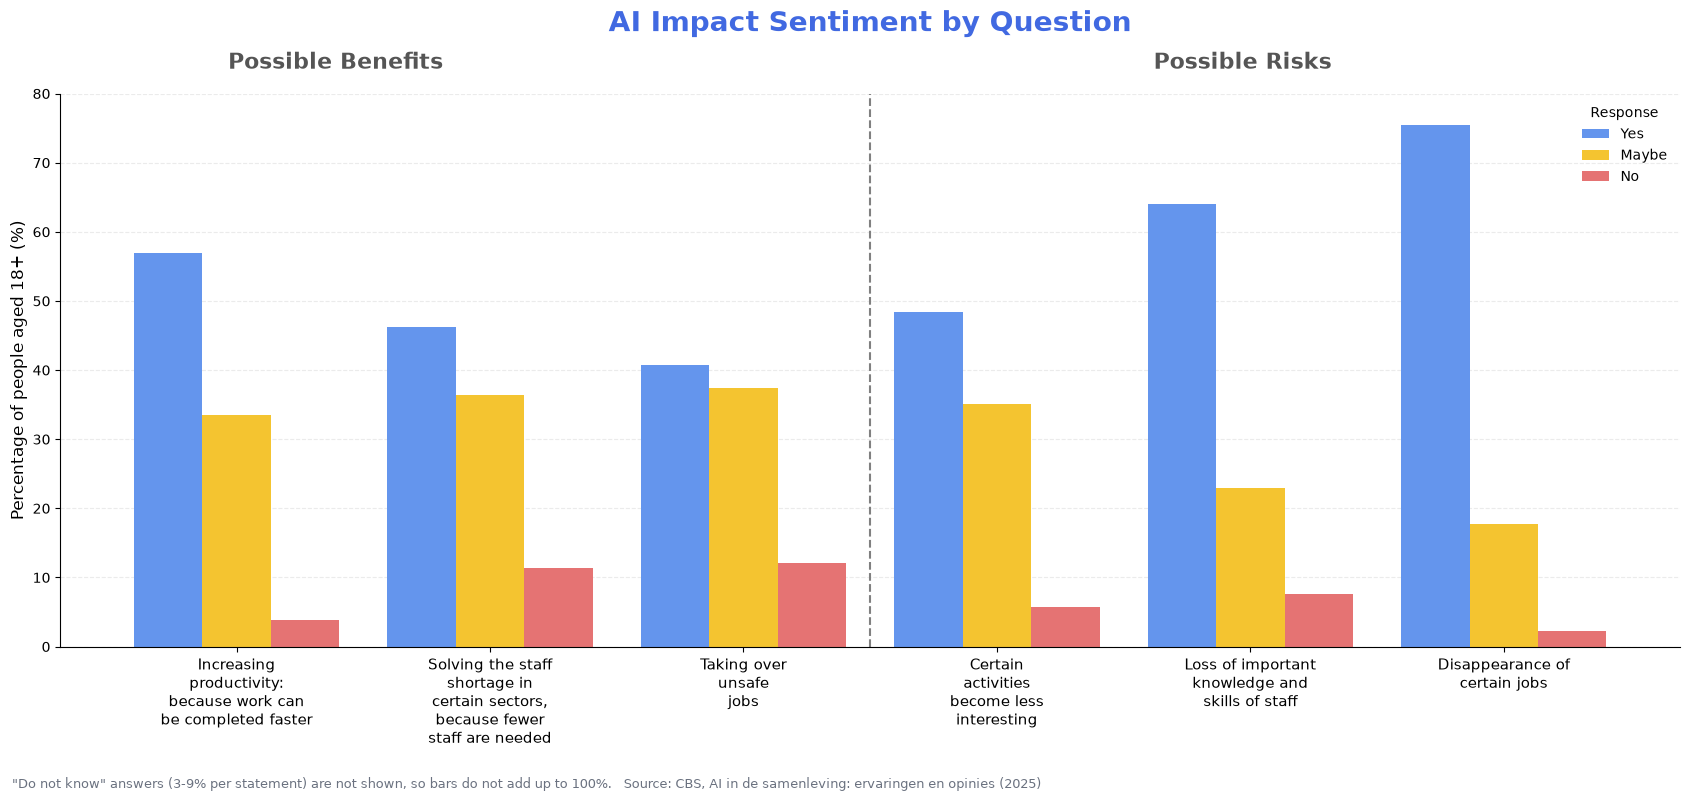

In [6]:
df1 = pd.read_csv(DATA_DIR / "clean_dataset1.csv")

dont_know = df1.loc[df1["response_en"] == "Do not know", "estimate"]
df1 = df1[df1["response_en"] != "Do not know"]

question_order = list(question_translation.values())
df1["question_en"] = pd.Categorical(df1["question_en"], categories=question_order, ordered=True)

plot_data = df1.pivot_table(index="question_en", columns="response_en", values="estimate", observed=False)
plot_data = plot_data[["Yes", "Maybe", "No"]]

fig, ax = plt.subplots(figsize=(17, 8))
x = np.arange(len(plot_data))
width = 0.27

ax.bar(x - width, plot_data["Yes"], width, label="Yes", color=POSITIVE)
ax.bar(x, plot_data["Maybe"], width, label="Maybe", color=UNCERTAIN)
ax.bar(x + width, plot_data["No"], width, label="No", color=NEGATIVE)

ax.set_ylabel("Percentage of people aged 18+ (%)", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(
    [
        "Increasing\nproductivity:\nbecause work can\nbe completed faster",
        "Solving the staff\nshortage in\ncertain sectors,\nbecause fewer\nstaff are needed",
        "Taking over\nunsafe\njobs",
        "Certain\nactivities\nbecome less\ninteresting",
        "Loss of important\nknowledge and\nskills of staff",
        "Disappearance of\ncertain jobs"
    ],
    fontsize=11
)
ax.set_ylim(0, 80)
style_title(ax, "AI Impact Sentiment by Question", pad=45, size=20)

# Benefit and risk categories
ax.text(0.17, 1.045, "Possible Benefits", transform=ax.transAxes, ha="center",
        fontsize=16, fontweight="bold", color="#555555")
ax.text(0.73, 1.045, "Possible Risks", transform=ax.transAxes, ha="center",
        fontsize=16, fontweight="bold", color="#555555")
ax.axvline(x=2.5, color="gray", linestyle="--", linewidth=1.5)

ax.yaxis.grid(True, linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title="Response", loc="upper right", frameon=False)

fig.tight_layout(rect=(0, 0.04, 1, 1))
add_footnote(
    fig,
    f"\"Do not know\" answers ({dont_know.min():.0f}-{dont_know.max():.0f}% per statement) are not shown, "
    f"so bars do not add up to 100%.   {SOURCE_SURVEY}"
)
save_figure(fig, "graph1_sentiment_by_statement")
plt.show()

**Graph 2: overall response balance**

How the score is built:

* **Reverse-coding.** For the three risk statements, "Yes" means the respondent *agrees that a risk exists*. Those answers are swapped so that "Yes" always means *positive about AI*. This assumes that rejecting a risk is equivalent to a positive view; someone who says "No" to *jobs will disappear* is not necessarily enthusiastic about AI, so the score measures how *unworried and optimistic* answers are rather than enthusiasm.
* **Uncertainty.** "Do not know" is added to "Maybe", since both express that the respondent is not sure.
* **Score.** Positive = 1, Uncertain = 0.5, Negative = 0. A score of 50% means answers are balanced.

Because one aggregate number can hide differences between statements, the score is also shown per statement (Graph 2b).

In [7]:
df2 = pd.read_csv(DATA_DIR / "clean_dataset1.csv")
df2 = df2.pivot(index="question_en", columns="response_en", values="estimate")

risks = [
    "Certain tasks are becoming less interesting.",
    "Loss of important staff knowledge and skills.",
    "Disappearance of certain jobs."
]
risk_mask = df2.index.isin(risks)

# Reverse-code risk statements so "Yes" always means positive about AI
df2.loc[risk_mask, ["Yes", "No"]] = df2.loc[risk_mask, ["No", "Yes"]].values

# "Do not know" counts as uncertain
df2["Maybe"] = df2["Maybe"] + df2["Do not know"]
df2 = df2[["Yes", "Maybe", "No"]]

# Per-statement score (used in Graph 2b)
statement_share = df2.div(df2.sum(axis=1), axis=0)
statement_score = statement_share["Yes"] * 1.0 + statement_share["Maybe"] * 0.5

# Aggregate score across all statements
totals = df2.sum()
yes_pct, maybe_pct, no_pct = totals / totals.sum()
score = yes_pct * 1.0 + maybe_pct * 0.5 + no_pct * 0.0

print(f"Positive:  {yes_pct * 100:.1f}%")
print(f"Uncertain: {maybe_pct * 100:.1f}%")
print(f"Negative:  {no_pct * 100:.1f}%")
print(f"Overall balance: {score * 100:.1f}%")

Positive:  27.0%
Uncertain: 36.6%
Negative:  36.4%
Overall balance: 45.3%


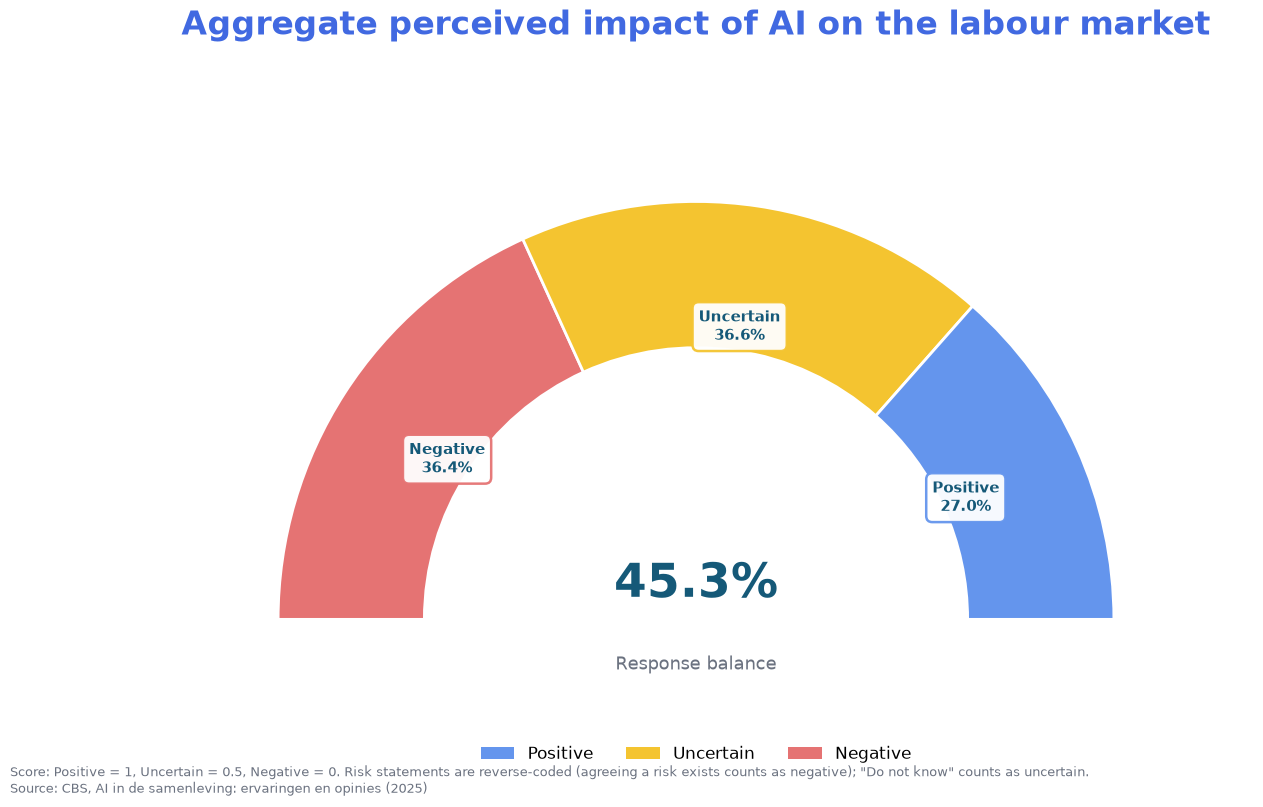

In [8]:
colors = {"Positive": POSITIVE, "Uncertain": UNCERTAIN, "Negative": NEGATIVE}
shares = {"Positive": yes_pct, "Uncertain": maybe_pct, "Negative": no_pct}
segments = [(label, shares[label] * 180) for label in ["Negative", "Uncertain", "Positive"]]

fig, ax = plt.subplots(figsize=(14, 8))
radius = 1.2
width = 0.42
current_angle = 180

for label, angle in segments:
    theta1 = current_angle - angle
    theta2 = current_angle

    ax.add_patch(Wedge(
        center=(0, 0), r=radius, theta1=theta1, theta2=theta2, width=width,
        facecolor=colors[label], edgecolor="white", linewidth=2
    ))

    # Label in the middle of the segment
    mid_angle = np.radians((theta1 + theta2) / 2)
    ax.text(
        0.85 * np.cos(mid_angle), 0.85 * np.sin(mid_angle),
        f"{label}\n{shares[label] * 100:.1f}%",
        fontsize=11, fontweight="bold", ha="center", va="center", color=TEXT_COLOR,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                  edgecolor=colors[label], linewidth=1.8, alpha=0.95)
    )
    current_angle = theta1

# Centre score
ax.text(0, 0.10, f"{score * 100:.1f}%", fontsize=34, fontweight="bold",
        ha="center", va="center", color=TEXT_COLOR)
ax.text(0, -0.13, "Response balance", fontsize=13, ha="center", va="center", color=MUTED)

ax.legend(
    handles=[Patch(facecolor=colors[label], label=label) for label in ["Positive", "Uncertain", "Negative"]],
    loc="lower center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=12, frameon=False
)

ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-0.2, 1.5)
ax.set_aspect("equal")
ax.axis("off")
style_title(ax, "Aggregate perceived impact of AI on the labour market", pad=45, size=24)

fig.tight_layout()
fig.subplots_adjust(top=0.88, bottom=0.14)
add_footnote(
    fig,
    "Score: Positive = 1, Uncertain = 0.5, Negative = 0. Risk statements are reverse-coded "
    "(agreeing a risk exists counts as negative); \"Do not know\" counts as uncertain.\n" + SOURCE_SURVEY
)
save_figure(fig, "graph2_response_balance")
plt.show()

**Graph 2b: response balance per statement** (50% = balanced; below 50% = leaning negative)

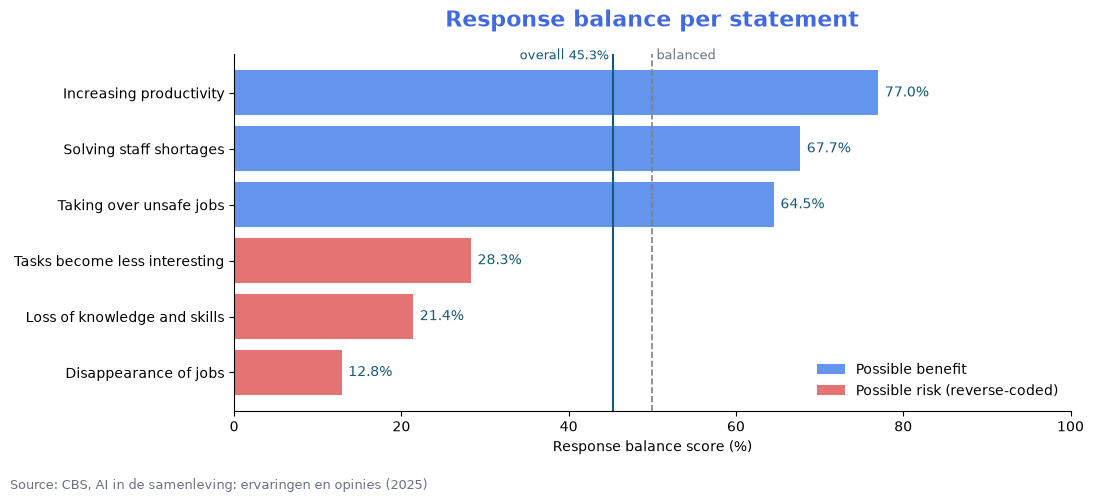

question_en
Increasing productivity, as work can be carried out faster.                          77.0
Solving the workforce shortage for certain sectors, as less personnel are needed.    67.7
Taking over unsafe jobs.                                                             64.5
Certain tasks are becoming less interesting.                                         28.3
Loss of important staff knowledge and skills.                                        21.4
Disappearance of certain jobs.                                                       12.8
Name: balance score (%), dtype: float64

In [9]:
short_labels = {
    "Increasing productivity, as work can be carried out faster.": "Increasing productivity",
    "Solving the workforce shortage for certain sectors, as less personnel are needed.": "Solving staff shortages",
    "Taking over unsafe jobs.": "Taking over unsafe jobs",
    "Certain tasks are becoming less interesting.": "Tasks become less interesting",
    "Loss of important staff knowledge and skills.": "Loss of knowledge and skills",
    "Disappearance of certain jobs.": "Disappearance of jobs"
}

per_statement = statement_score.reindex(question_order).iloc[::-1] * 100

fig, ax = plt.subplots(figsize=(11, 5))
bar_colors = [NEGATIVE if q in risks else POSITIVE for q in per_statement.index]
ax.barh([short_labels[q] for q in per_statement.index], per_statement, color=bar_colors)
ax.axvline(50, color="gray", linestyle="--", linewidth=1.2)
ax.text(50.5, len(per_statement) - 0.4, "balanced", color=MUTED, fontsize=9)
ax.axvline(score * 100, color=TEXT_COLOR, linewidth=1.5)
ax.text(score * 100 - 0.5, len(per_statement) - 0.4, f"overall {score * 100:.1f}%",
        color=TEXT_COLOR, fontsize=9, ha="right")

for y, value in enumerate(per_statement):
    ax.text(value + 0.8, y, f"{value:.1f}%", va="center", fontsize=10, color=TEXT_COLOR)

ax.set_xlim(0, 100)
ax.set_xlabel("Response balance score (%)")
ax.legend(
    handles=[Patch(facecolor=POSITIVE, label="Possible benefit"), Patch(facecolor=NEGATIVE, label="Possible risk (reverse-coded)")],
    loc="lower right", frameon=False
)
style_title(ax, "Response balance per statement", size=16)

fig.tight_layout(rect=(0, 0.05, 1, 1))
add_footnote(fig, SOURCE_SURVEY)
save_figure(fig, "graph2b_balance_per_statement")
plt.show()

per_statement.iloc[::-1].round(1).rename("balance score (%)")

## Question 2: use of AI by people and companies

**Load and inspect the second dataset**

In [10]:
raw_2 = pd.read_excel(DATA_DIR / "Question 2 dataset.xlsx", header=None)
raw_2

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,4.12 Opvattingen over AI-toepassingen en de ar...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Huidig gebruik van AI voor eigen werk,NaN,NaN,NaN,NaN,NaN,Verwachting dat AI in de komende 10 jaar (meer...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Ja,gasaansluitingnee_po,gasaansluitingnee_pb,Nee,gasaansluitingnee_po,gasaansluitingnee_pb,Ja,gasaansluitingnee_po,gasaansluitingnee_pb,Nee,NaN,NaN,Weet niet,gasaansluitingnee_po,gasaansluitingnee_pb
3,NaN,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens,Schatting,Ondergrens,Bovengrens
4,NaN,% van personen van 18 jaar of ouder,NaN,NaN,NaN,NaN,NaN,% van personen van 18 jaar of ouder met betaal...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Totaal,42.9,40.9,45,57.1,55,59.1,69.6,67.7,71.4,15,13.6,16.6,15.4,13.9,16.9
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Geslacht,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Mannen,45.9,43.1,48.7,54.1,51.3,56.9,71.1,68.4,73.6,15.2,13.2,17.4,13.7,11.9,15.8


**Clean dataset 2: reshape, label each row with its demographic section, and translate**

Note: CBS reports the two questions for different groups. Current use is a share of **all people aged 18+**; the 10-year expectation is a share of **people aged 18+ in paid work**. This is kept in a `population` column and shown on Graph 3.

In [11]:
question_names = {
    "Huidig gebruik van AI voor eigen werk": "Current AI use",
    "Verwachting dat AI in de komende 10 jaar (meer) gebruikt gaat worden voor eigen werk": "Future AI expectation"
}

unit_translation = {
    "% van personen van 18 jaar of ouder": "people aged 18+",
    "% van personen van 18 jaar of ouder met betaald werk": "people aged 18+ in paid work"
}

section_translation = {
    "Totaal": "Total",
    "Geslacht": "Gender",
    "Leeftijd": "Age",
    "Onderwijsniveau": "Education",
    "Herkomst": "Origin",
    "Financiële welvaart": "Financial welfare"
}

group_translation = {
    "Totaal": "Total",
    "Mannen": "Men",
    "Vrouwen": "Women",
    "18 tot 25 jaar": "18-25 years old",
    "25 tot 45 jaar": "25-45 years old",
    "45 tot 65 jaar": "45-65 years old",
    "65 jaar of ouder": "65+ years old",
    "Basisonderwijs, vmbo, mbo1": "Primary education, vmbo, mbo1",
    "Havo, vwo, mbo2-4": "Havo, vwo, mbo2-4",
    "Hbo, wo": "Hbo, wo",
    "Nederlandse herkomst": "Dutch origin",
    "Geboren in Nederland, ouder(s) in het buitenland": "Born in the Netherlands, parent(s) abroad",
    "Geboren in het buitenland": "Born abroad",
    "1e 20%-groep (laagst)": "1st 20% group (lowest)",
    "2e 20%-groep": "2nd 20% group",
    "3e 20%-groep": "3rd 20% group",
    "4e 20%-groep": "4th 20% group",
    "5e 20%-groep (hoogst)": "5th 20% group (highest)"
}

tidy_2 = tidy_cbs_table(raw_2)
tidy_2 = pd.DataFrame({
    "question": tidy_2["question_nl"].map(question_names),
    "demographic_type": tidy_2["section"].map(section_translation),
    "demographic_group": tidy_2["row_label"].map(group_translation),
    "response": tidy_2["response_nl"].map(response_translation),
    "estimate": tidy_2["estimate"],
    "population": tidy_2["unit_nl"].map(unit_translation)
})

assert tidy_2.notna().all().all(), "Untranslated label or missing estimate in dataset 2"

# The national total is not one of the compared groups
tidy_2 = tidy_2[tidy_2["demographic_type"] != "Total"].reset_index(drop=True)

tidy_2.to_csv(DATA_DIR / "clean_dataset2.csv", index=False)
tidy_2

,question,demographic_type,demographic_group,response,estimate,population
0,Current AI use,Gender,Men,Yes,45.9,people aged 18+
1,Current AI use,Gender,Women,Yes,39.6,people aged 18+
2,Current AI use,Age,18-25 years old,Yes,34.6,people aged 18+
3,Current AI use,Age,25-45 years old,Yes,51.3,people aged 18+
4,Current AI use,Age,45-65 years old,Yes,39.8,people aged 18+
...,...,...,...,...,...,...
80,Future AI expectation,Financial welfare,1st 20% group (lowest),Do not know,18.3,people aged 18+ in paid work
81,Future AI expectation,Financial welfare,2nd 20% group,Do not know,20.0,people aged 18+ in paid work
82,Future AI expectation,Financial welfare,3rd 20% group,Do not know,17.2,people aged 18+ in paid work
83,Future AI expectation,Financial welfare,4th 20% group,Do not know,14.3,people aged 18+ in paid work


**Graph 3: the AI adoption gap per demographic group (interactive, Plotly)**

In [12]:
df3 = tidy_2[tidy_2["response"] == "Yes"].pivot_table(
    index=["demographic_type", "demographic_group"],
    columns="question",
    values="estimate"
).reset_index()
df3["Gap"] = df3["Future AI expectation"] - df3["Current AI use"]

population = tidy_2.groupby("question")["population"].first()

groups = {
    "1. GENDER": ["Men", "Women"],
    "2. AGE GROUP": ["18-25 years old", "25-45 years old", "45-65 years old", "65+ years old"],
    "3. EDUCATION LEVEL": ["Primary education, vmbo, mbo1", "Havo, vwo, mbo2-4", "Hbo, wo"],
    "4. ORIGIN GROUP": ["Dutch origin", "Born in the Netherlands, parent(s) abroad", "Born abroad"],
    "5. HOUSEHOLD INCOME": ["1st 20% group (lowest)", "2nd 20% group", "3rd 20% group",
                            "4th 20% group", "5th 20% group (highest)"]
}

section_fill = {
    "1. GENDER": "rgba(190,220,255,0.45)",
    "2. AGE GROUP": "rgba(205,240,205,0.45)",
    "3. EDUCATION LEVEL": "rgba(225,210,255,0.45)",
    "4. ORIGIN GROUP": "rgba(255,245,180,0.45)",
    "5. HOUSEHOLD INCOME": "rgba(255,210,230,0.45)"
}

# One row per section header, followed by its groups
rows = []
for section, members in groups.items():
    rows.append({"demographic_group": section, "header": True})
    for member in members:
        row = df3[df3["demographic_group"] == member].iloc[0]
        rows.append({
            "demographic_group": member,
            "Current AI use": row["Current AI use"],
            "Future AI expectation": row["Future AI expectation"],
            "Gap": row["Gap"],
            "header": False
        })
plot_df = pd.DataFrame(rows)

fig = go.Figure()

# Section shading and headers
header_rows = plot_df.index[plot_df["header"]].tolist() + [len(plot_df)]
for start, end in zip(header_rows[:-1], header_rows[1:]):
    section = plot_df.loc[start, "demographic_group"]
    fig.add_hrect(y0=start + 0.5, y1=end - 0.5, fillcolor=section_fill[section],
                  opacity=0.6, line_width=0, layer="below")
    fig.add_annotation(xref="paper", yref="y", x=-0.14, y=start, text=f"<b>{section}</b>",
                       showarrow=False, xanchor="left", align="left",
                       font=dict(size=16, color=TITLE_COLOR))

data_rows = plot_df[~plot_df["header"]]

# Dumbbell lines and gap labels (percentage points)
for i, row in data_rows.iterrows():
    fig.add_shape(type="line", x0=row["Current AI use"], x1=row["Future AI expectation"],
                  y0=i, y1=i, line=dict(color=CONTEXT_GREY, width=3))
    fig.add_annotation(x=(row["Current AI use"] + row["Future AI expectation"]) / 2, y=i,
                       text=f"+{row['Gap']:.0f} pp", showarrow=False, bgcolor="white",
                       font=dict(size=10, color=TEXT_COLOR))

fig.add_trace(go.Scatter(
    x=data_rows["Current AI use"], y=data_rows.index, mode="markers",
    marker=dict(color=UNCERTAIN, size=11),
    name=f"Current AI use (% of {population['Current AI use']})",
    text=data_rows["demographic_group"],
    hovertemplate="<b>%{text}</b><br>Current AI use: %{x:.0f}%<extra></extra>"
))
fig.add_trace(go.Scatter(
    x=data_rows["Future AI expectation"], y=data_rows.index, mode="markers",
    marker=dict(color=POSITIVE, size=11),
    name=f"Expects (more) AI use in 10 years (% of {population['Future AI expectation']})",
    text=data_rows["demographic_group"],
    hovertemplate="<b>%{text}</b><br>Expected AI use: %{x:.0f}%<extra></extra>"
))

ticktext = ["" if row["header"] else row["demographic_group"] for _, row in plot_df.iterrows()]

fig.update_layout(
    title=dict(
        text="<b>THE AI ADOPTION GAP: Current Use (2025) vs Future Expectation (Next 10 Years)</b>",
        x=0.5, font=dict(size=18, color=TITLE_COLOR)
    ),
    xaxis=dict(title="Share answering \"yes\" (%)", range=[0, 100], showgrid=True, gridcolor="lightgray"),
    yaxis=dict(tickmode="array", tickvals=list(plot_df.index), ticktext=ticktext, autorange="reversed"),
    plot_bgcolor="white",
    paper_bgcolor="white",
    width=1400,
    height=1000,
    hovermode="closest",
    legend=dict(orientation="h", y=1.05, x=1, xanchor="right", font=dict(size=12)),
    margin=dict(l=260, r=80, t=100, b=120)
)

fig.add_annotation(
    xref="paper", yref="paper", x=-0.14, y=-0.11, xanchor="left", align="left", showarrow=False,
    font=dict(size=11, color=MUTED),
    text=(
        f"Gap in percentage points (pp). Note: current use is measured among {population['Current AI use']}, "
        f"the expectation among {population['Future AI expectation']},<br>so each gap compares two slightly different groups. "
        + SOURCE_SURVEY
    )
)

fig.write_html(FIG_DIR / "graph3_adoption_gap.html", include_plotlyjs="cdn")
fig.write_image(FIG_DIR / "graph3_adoption_gap.png", scale=1)
fig.show()

**Load and inspect the third dataset: use of specific AI technologies by companies**

In [13]:
raw_3 = pd.read_csv(DATA_DIR / "different AI technologies.csv")
raw_3.shape

(6, 15)

In [14]:
raw_3

,Jaar,"Use of specific AI technologies, Machine learning (Use of AI technology (%))","Use of specific AI technologies, Machine learning (95% confidence interval) (Use of AI technology (%))","Use of specifiec AI technologies, Image recognition (Use of AI technology (%))","Use of specific AI technologies, Afbeeldingherkenning (95% confidence interval) (Use of AI technology (%))","Use of specific AI technologies, Robots autonomous vehicles (Use of AI technology (%))","Use of specific AI technologies, Robots autonomous vehicles (95% confidence interval) (Use of AI technology (%))","Use of specific AI technologies, Robots process automation (Use of AI technology (%))","Use of specific AI technologies, Robots process automation (95% confidence interval) (Use of AI technology (%))","Use of specific AI technologies, Speech recognition (Use of AI technology (%))","Use of specific AI technologies, Speech recognition (95% confidence interval) (Use of AI technology (%))","Use of specific AI technologies, Text mining (Use of AI technology (%))","Use of specific AI technologies, Text mining (95% confidence interval) (Use of AI technology (%))","Use of specific AI technologies, Natural language generation (Use of AI technology (%))","Use of specific AI technologies, Natural language generation (95% confidence interval) (Use of AI technology (%))"
0,2020,5.6,5.2 - 6.2,NaN,-,1.6,1.4 - 1.9,4.2,3.8 - 4.6,3.1,2.7 - 3.5,NaN,NaN,NaN,NaN
1,2021,5.8,5.3 - 6.3,3.7,3.3 - 4.1,2.1,1.8 - 2.4,6.3,5.8 - 6.9,3.1,2.7 - 3.5,3.9,3.5 - 4.4,2.2,1.9 - 2.5
2,2022*,7.2,6.6 - 7.8,4.3,3.9 - 4.7,2.5,2.2 - 2.9,8.3,7.7 - 9,3.7,3.3 - 4.2,5.3,4.8 - 5.9,2.7,2.4 - 3.1
3,2023*,5.6,5.1 - 6.1,3.7,3.3 - 4.1,2.2,2 - 2.6,5.6,5.1 - 6.1,3.7,3.3 - 4.2,5.3,4.8 - 5.8,4.2,3.8 - 4.7
4,2024*,6.3,5.8 - 6.8,4.5,4.1 - 5,2.0,1.8 - 2.3,6.0,5.6 - 6.5,6.5,6 - 7,13.5,12.7 - 14.4,12.3,11.5 - 13.1
5,* provisional figures,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Select the estimate columns by name and convert years**

Columns are selected by their header text (estimate columns, not the confidence-interval columns) and the technology name is extracted from the header. The footnote row is dropped, and years marked `*` are flagged as provisional.

In [15]:
def company_years(raw):
    """Keep year rows only and add a numeric year plus a provisional flag."""
    year_col = raw.columns[0]
    rows = raw[raw[year_col].astype(str).str.match(r"^\d{4}")].copy()
    rows["year"] = rows[year_col].astype(str).str[:4].astype(int)
    rows["year_label"] = rows[year_col].astype(str)
    rows["provisional"] = rows["year_label"].str.endswith("*")
    return rows


estimate_cols = [
    col for col in raw_3.columns
    if col.endswith("(Use of AI technology (%))") and "confidence interval" not in col
]
tech_names = {col: col.split(", ", 1)[1].split(" (Use of AI", 1)[0] for col in estimate_cols}

df4 = company_years(raw_3)[["year", "year_label", "provisional"] + estimate_cols].rename(columns=tech_names)
df4 = df4.set_index("year")
technologies = list(tech_names.values())
df4[technologies] = df4[technologies].apply(pd.to_numeric, errors="coerce")
df4

,year_label,provisional,Machine learning,Image recognition,Robots autonomous vehicles,Robots process automation,Speech recognition,Text mining,Natural language generation
year,,,,,,,,,
2020,2020,False,5.6,NaN,1.6,4.2,3.1,NaN,NaN
2021,2021,False,5.8,3.7,2.1,6.3,3.1,3.9,2.2
2022,2022*,True,7.2,4.3,2.5,8.3,3.7,5.3,2.7
2023,2023*,True,5.6,3.7,2.2,5.6,3.7,5.3,4.2
2024,2024*,True,6.3,4.5,2.0,6.0,6.5,13.5,12.3


**Graph 4: use of different AI technologies by companies over time** (language-based technologies highlighted, others in grey)

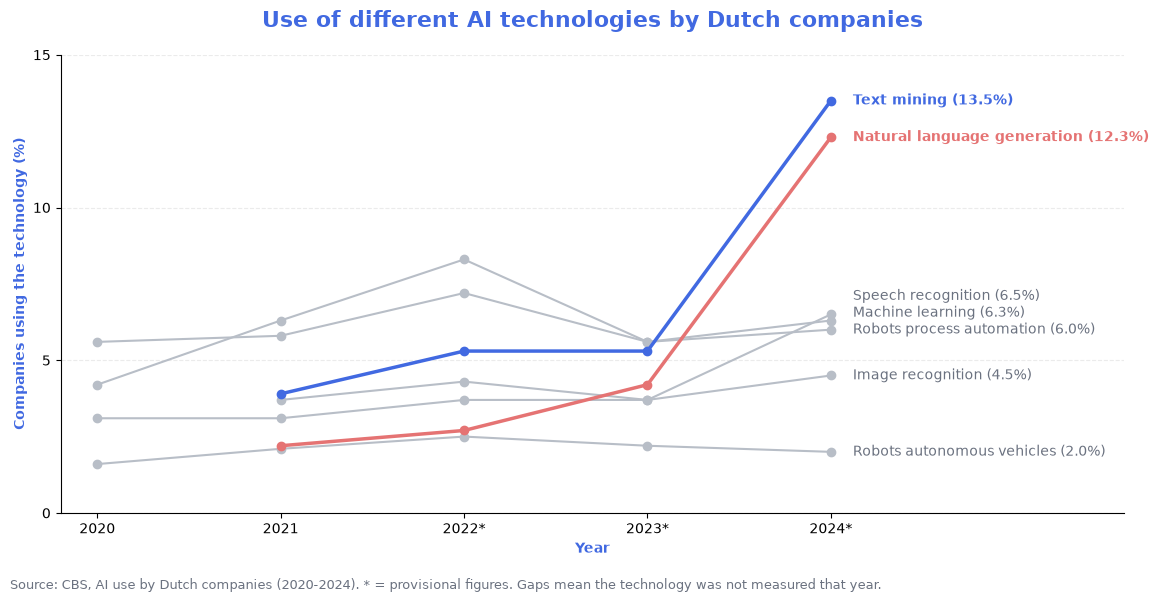

In [16]:
def spread_labels(values, min_gap):
    """Nudge label positions apart so they do not overlap; returns positions in the input order."""
    order = np.argsort(values)
    positions = np.array(values, dtype=float)[order]
    for i in range(1, len(positions)):
        positions[i] = max(positions[i], positions[i - 1] + min_gap)
    result = np.empty_like(positions)
    result[order] = positions
    return result


fig, ax = plt.subplots(figsize=(12, 6))
x = df4["year_label"]

# Grey context lines first, highlighted lines on top
for tech in sorted(technologies, key=lambda t: t in HIGHLIGHT):
    color = HIGHLIGHT.get(tech, CONTEXT_GREY)
    ax.plot(x, df4[tech], marker="o", color=color,
            linewidth=2.5 if tech in HIGHLIGHT else 1.5, zorder=3 if tech in HIGHLIGHT else 2)

# Direct labels at the end of each line instead of a legend
last_values = df4[technologies].iloc[-1]
label_y = spread_labels(last_values.values, min_gap=0.55)
for tech, value, y in zip(technologies, last_values, label_y):
    is_highlight = tech in HIGHLIGHT
    ax.text(len(x) - 1 + 0.12, y, f"{tech} ({value:.1f}%)", va="center",
            fontsize=10, color=HIGHLIGHT.get(tech, MUTED),
            fontweight="bold" if is_highlight else "normal")

ax.set_xlim(-0.2, len(x) - 1 + 1.6)
ax.set_ylim(0, 15)
ax.set_yticks(range(0, 16, 5))
ax.set_xlabel("Year", fontweight="bold", color=TITLE_COLOR)
ax.set_ylabel("Companies using the technology (%)", fontweight="bold", color=TITLE_COLOR)
ax.yaxis.grid(True, linestyle="--", alpha=0.25)
style_title(ax, "Use of different AI technologies by Dutch companies", size=16)

fig.tight_layout(rect=(0, 0.04, 1, 1))
add_footnote(fig, SOURCE_COMPANIES + ". Gaps mean the technology was not measured that year.")
save_figure(fig, "graph4_ai_technologies")
plt.show()

**Load and inspect the fourth dataset: overall share of companies using AI**

In [17]:
raw_4 = pd.read_csv(DATA_DIR / "number of companies - timeline.csv")
raw_4.shape

(6, 5)

In [18]:
raw_4

,Year,7 technologies (Use of AI technology (%)),7 technologies (95% confidence interval) (Use of AI technology (%)),4 technologies (Use of AI technology (%)),4 technologies (95% confidence interval) (Use of AI technology (%))
0,2020,NaN,NaN,9.9,9.3 - 10.6
1,2021,13.1,12.3 - 13.9,10.7,10 - 11.4
2,2022*,15.8,14.9 - 16.7,13.3,12.6 - 14.1
3,2023*,14.0,13.2 - 14.8,10.6,9.9 - 11.3
4,2024*,22.7,21.7 - 23.8,12.9,12.2 - 13.6
5,* provisional figures,NaN,NaN,NaN,NaN


**Select the overall adoption measures and merge with dataset 3 on year**

CBS publishes two overall measures: the share of companies using at least one of **4** technologies (available from 2020) and at least one of **7** technologies (from 2021, after text mining, natural language generation and image recognition were added). The two are not comparable with each other, so Graph 5 uses the 7-technology measure for both years it compares.

In [19]:
df5 = company_years(raw_4).set_index("year")
df5 = df5.rename(columns={
    "7 technologies (Use of AI technology (%))": "overall_7_tech",
    "4 technologies (Use of AI technology (%))": "overall_4_tech"
})[["overall_7_tech", "overall_4_tech"]].apply(pd.to_numeric, errors="coerce")

merged_df = df4.join(df5)
merged_df

,year_label,provisional,Machine learning,Image recognition,Robots autonomous vehicles,Robots process automation,Speech recognition,Text mining,Natural language generation,overall_7_tech,overall_4_tech
year,,,,,,,,,,,
2020,2020,False,5.6,NaN,1.6,4.2,3.1,NaN,NaN,NaN,9.9
2021,2021,False,5.8,3.7,2.1,6.3,3.1,3.9,2.2,13.1,10.7
2022,2022*,True,7.2,4.3,2.5,8.3,3.7,5.3,2.7,15.8,13.3
2023,2023*,True,5.6,3.7,2.2,5.6,3.7,5.3,4.2,14.0,10.6
2024,2024*,True,6.3,4.5,2.0,6.0,6.5,13.5,12.3,22.7,12.9


**Graph 5: like-for-like comparison of company AI adoption, 2021 vs 2024**

2021 is the first year in which CBS measures all 7 technologies, so both circles use the same definition. Circle area scales with overall adoption, and technology colours match Graph 4.

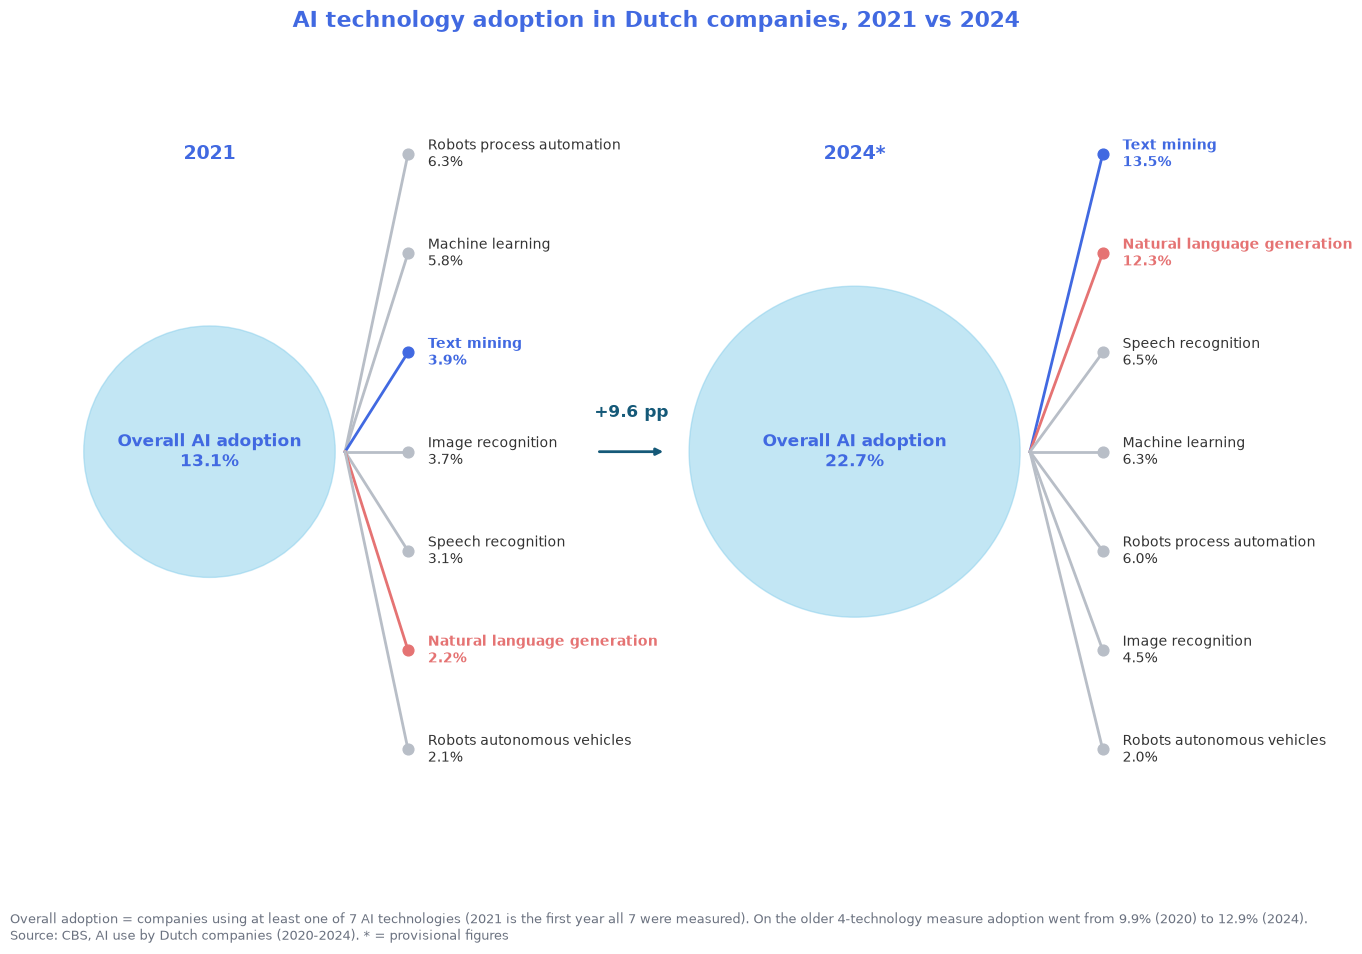

In [20]:
start_year, end_year = 2021, 2024
start, end = merged_df.loc[start_year], merged_df.loc[end_year]
change = end["overall_7_tech"] - start["overall_7_tech"]

fig, ax = plt.subplots(figsize=(14, 9.5))

sides = [
    (start, 2.0, 4.0),
    (end, 8.5, 11.0)
]

for row, cx, branch_x in sides:
    overall = row["overall_7_tech"]
    radius = np.sqrt(overall) * 0.35
    ax.add_patch(plt.Circle((cx, 5), radius, alpha=0.5, color="skyblue"))
    ax.text(cx, 5, f"Overall AI adoption\n{overall:.1f}%", ha="center", va="center",
            fontsize=12, weight="bold", color=TITLE_COLOR)
    ax.text(cx, 8, row["year_label"], ha="center", va="center", fontsize=14,
            weight="bold", color=TITLE_COLOR)

    tech_values = row[technologies].astype(float).dropna().sort_values(ascending=False)
    for y, (tech, value) in zip(range(8, 8 - len(tech_values), -1), tech_values.items()):
        color = HIGHLIGHT.get(tech, CONTEXT_GREY)
        ax.plot([cx + radius + 0.1, branch_x], [5, y], linewidth=2, color=color)
        ax.scatter(branch_x, y, s=60, color=color, zorder=3)
        ax.text(branch_x + 0.2, y, f"{tech}\n{value:.1f}%", va="center", fontsize=10,
                color=HIGHLIGHT.get(tech, "#333333"),
                fontweight="bold" if tech in HIGHLIGHT else "normal")

# Change between the two years
ax.annotate("", xy=(6.6, 5), xytext=(5.9, 5),
            arrowprops=dict(arrowstyle="-|>", color=TEXT_COLOR, lw=2))
ax.text(6.25, 5.35, f"+{change:.1f} pp", ha="center", fontsize=12, weight="bold", color=TEXT_COLOR)

ax.set_xlim(0, 13)
ax.set_ylim(1, 9)
# Equal aspect keeps the circles round, so their areas can be compared
ax.set_aspect("equal")
ax.axis("off")
style_title(ax, f"AI technology adoption in Dutch companies, {start_year} vs {end_year}", size=16)

fig.tight_layout(rect=(0, 0.06, 1, 1))
add_footnote(
    fig,
    f"Overall adoption = companies using at least one of 7 AI technologies ({start_year} is the first year all 7 were measured). "
    f"On the older 4-technology measure adoption went from {merged_df.loc[2020, 'overall_4_tech']:.1f}% (2020) "
    f"to {end['overall_4_tech']:.1f}% ({end_year}).\n" + SOURCE_COMPANIES
)
save_figure(fig, "graph5_adoption_2021_vs_2024")
plt.show()